# Phase 2: Exploratory Data Analysis

This notebook performs a systematic exploratory analysis of the European
Credit Card Fraud Detection dataset.

The objectives are to:

- Validate the dataset structure and target labels.
- Understand the severity of class imbalance.
- Analyze transaction amounts and elapsed-time patterns.
- Inspect the distributions of anonymized PCA features.
- Identify features that differ between legitimate and fraudulent transactions.
- Examine correlations and potential outlier candidates.
- Save figures and a written EDA report for later phases.

This notebook is descriptive. It does not clean the dataset, remove outliers,
train models, select features, or make decisions using the final test set.

In [1]:
import json
import logging
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Imports and project configuration

This cell imports the libraries required for data analysis and visualization
and defines the main project paths.

The notebook uses:

- `pandas` and `NumPy` for data manipulation and numerical analysis.
- `Matplotlib` and `Seaborn` for visualizations.
- `pathlib` for portable file paths.
- `logging` for execution messages.

The raw dataset is expected at `data/raw/creditcard.csv`. Generated figures
are saved under `reports/figures/`, and the final EDA report is saved to
`reports/eda_report.md`.

In [2]:
PROJECT_ROOT = Path.cwd().parent

DATA_RAW_DIR = PROJECT_ROOT / "data" / "raw"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

RAW_DATA_PATH = DATA_RAW_DIR / "creditcard.csv"
EDA_REPORT_PATH = REPORTS_DIR / "eda_report.md"

TARGET_COLUMN = "Class"
AMOUNT_COLUMN = "Amount"
TIME_COLUMN = "Time"
PCA_FEATURES = [f"V{i}" for i in range(1, 29)]

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(message)s",
)

logger = logging.getLogger(__name__)

logger.info("Project root: %s", PROJECT_ROOT)
logger.info("Raw dataset path: %s", RAW_DATA_PATH)

2026-11-01 09:10:09,412 | INFO | Project root: c:\Users\use\Desktop\Credit Card Fraud Detection
2026-11-01 09:10:09,416 | INFO | Raw dataset path: c:\Users\use\Desktop\Credit Card Fraud Detection\data\raw\creditcard.csv


## Load and validate the dataset

This cell loads the raw dataset and performs initial validation.

It checks that:

- The raw CSV file exists.
- The dataset is not empty.
- All expected columns are present.
- The `Class` target column contains only `0` and `1`.

Unexpected additional columns generate a warning rather than being silently
removed. The original dataset is read only; it is not modified.

In [3]:
EXPECTED_COLUMNS = [TIME_COLUMN, *PCA_FEATURES, AMOUNT_COLUMN, TARGET_COLUMN]


def load_and_validate_dataset(file_path: Path) -> pd.DataFrame:
    """Load the raw dataset and validate its basic structure."""
    if not file_path.exists():
        raise FileNotFoundError(f"Raw dataset not found: {file_path}")

    dataframe = pd.read_csv(file_path)

    if dataframe.empty:
        raise ValueError("The dataset is empty.")

    missing_columns = set(EXPECTED_COLUMNS) - set(dataframe.columns)
    if missing_columns:
        raise ValueError(f"Missing expected columns: {sorted(missing_columns)}")

    unexpected_columns = set(dataframe.columns) - set(EXPECTED_COLUMNS)
    if unexpected_columns:
        logger.warning("Unexpected columns detected: %s", sorted(unexpected_columns))

    invalid_target_values = set(dataframe[TARGET_COLUMN].unique()) - {0, 1}
    if invalid_target_values:
        raise ValueError(
            f"Target column contains unexpected values: {sorted(invalid_target_values)}"
        )

    return dataframe


creditcard_df = load_and_validate_dataset(RAW_DATA_PATH)

logger.info(
    "Dataset loaded successfully: %s rows, %s columns",
    creditcard_df.shape[0],
    creditcard_df.shape[1],
)

2026-11-01 09:10:14,741 | INFO | Dataset loaded successfully: 284807 rows, 31 columns


## Dataset overview

This cell creates a concise structural and data-quality overview.

It reports:

- Row and column counts.
- Numerical and categorical column counts.
- Total missing values.
- Columns containing missing values.
- Duplicate-row count and percentage.
- Target-column name and valid target values.

These results establish a baseline understanding of the dataset before
detailed analysis.

In [4]:
def create_dataset_overview(dataframe: pd.DataFrame) -> dict:
    """Create a concise structural and quality overview."""
    missing_counts = dataframe.isnull().sum()
    duplicate_count = int(dataframe.duplicated().sum())

    return {
        "row_count": int(dataframe.shape[0]),
        "column_count": int(dataframe.shape[1]),
        "numerical_column_count": int(
            dataframe.select_dtypes(include=np.number).shape[1]
        ),
        "categorical_column_count": int(
            dataframe.select_dtypes(exclude=np.number).shape[1]
        ),
        "total_missing_values": int(missing_counts.sum()),
        "columns_with_missing_values": missing_counts[missing_counts > 0].to_dict(),
        "duplicate_row_count": duplicate_count,
        "duplicate_row_percentage": duplicate_count / len(dataframe) * 100,
        "target_column": TARGET_COLUMN,
        "target_unique_values": sorted(int(value) for value in dataframe[TARGET_COLUMN].unique()),
    }


dataset_overview = create_dataset_overview(creditcard_df)

print(json.dumps(dataset_overview, indent=2))

{
  "row_count": 284807,
  "column_count": 31,
  "numerical_column_count": 31,
  "categorical_column_count": 0,
  "total_missing_values": 0,
  "columns_with_missing_values": {},
  "duplicate_row_count": 1081,
  "duplicate_row_percentage": 0.379555277784605,
  "target_column": "Class",
  "target_unique_values": [
    0,
    1
  ]
}


## Class distribution and imbalance

This cell calculates the number and percentage of legitimate and fraudulent
transactions.

- `Class = 0` represents a legitimate transaction.
- `Class = 1` represents a fraudulent transaction.

The fraud-to-legitimate ratio quantifies the class imbalance. Because
fraudulent transactions are extremely rare, accuracy alone is not an
appropriate evaluation metric. Later phases must use precision, recall,
F1-score, PR-AUC, ROC-AUC, and confusion matrices.


In [5]:
def analyze_class_distribution(dataframe: pd.DataFrame) -> pd.DataFrame:
    """Calculate class counts, percentages, and imbalance ratio."""
    class_counts = dataframe[TARGET_COLUMN].value_counts().sort_index()
    class_percentages = dataframe[TARGET_COLUMN].value_counts(normalize=True).sort_index() * 100

    legitimate_count = int(class_counts.get(0, 0))
    fraudulent_count = int(class_counts.get(1, 0))

    class_summary = pd.DataFrame(
        {
            "count": class_counts,
            "percentage": class_percentages,
        }
    )
    class_summary.index = class_summary.index.map(
        {0: "Legitimate (0)", 1: "Fraudulent (1)"}
    )
    class_summary["fraud_to_legitimate_ratio"] = np.nan
    class_summary.loc["Fraudulent (1)", "fraud_to_legitimate_ratio"] = (
        fraudulent_count / legitimate_count if legitimate_count else np.inf
    )

    return class_summary


class_distribution = analyze_class_distribution(creditcard_df)
class_distribution

,count,percentage,fraud_to_legitimate_ratio
Class,,,
Legitimate (0),284315,99.827251,NaN
Fraudulent (1),492,0.172749,0.00173


## Visualize class distribution

This cell creates count and percentage charts for the target variable.

The visualization makes the severe class imbalance visible. The figure is
saved to `reports/figures/class_distribution.png` for later reporting.

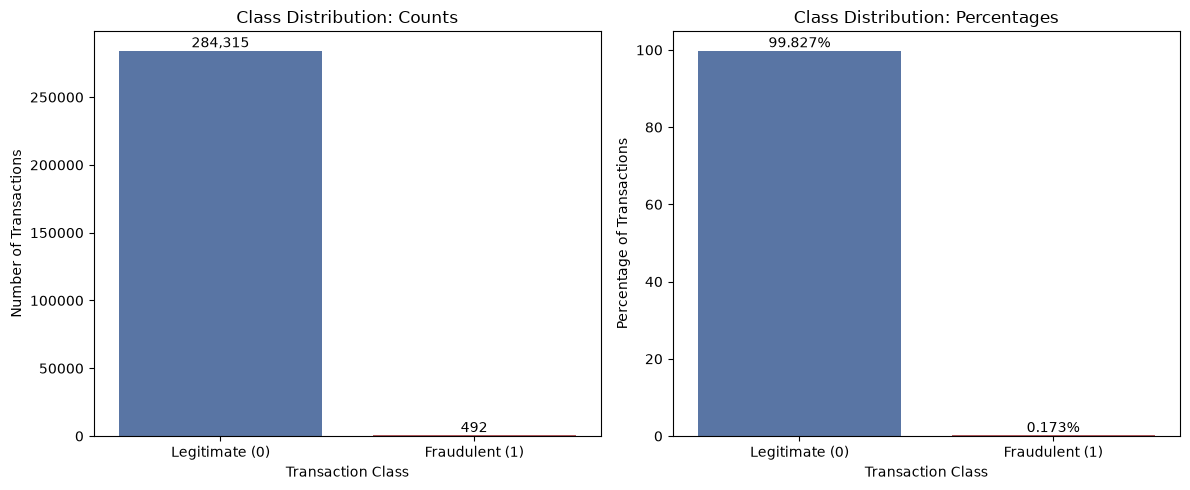

2026-11-01 09:10:19,280 | INFO | Saved class distribution figure: c:\Users\use\Desktop\Credit Card Fraud Detection\reports\figures\class_distribution.png


In [6]:
def plot_class_distribution(
    dataframe: pd.DataFrame,
    output_path: Path,
) -> None:
    """Plot class counts and percentages."""
    counts = dataframe[TARGET_COLUMN].value_counts().sort_index()
    percentages = dataframe[TARGET_COLUMN].value_counts(normalize=True).sort_index() * 100
    labels = ["Legitimate (0)", "Fraudulent (1)"]

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    sns.barplot(
        x=labels,
        y=counts.values,
        hue=labels,
        palette=["#4C72B0", "#C44E52"],
        legend=False,
        ax=axes[0],
    )
    axes[0].set_title("Class Distribution: Counts")
    axes[0].set_xlabel("Transaction Class")
    axes[0].set_ylabel("Number of Transactions")

    for index, value in enumerate(counts.values):
        axes[0].text(index, value, f"{value:,}", ha="center", va="bottom")

    sns.barplot(
        x=labels,
        y=percentages.values,
        hue=labels,
        palette=["#4C72B0", "#C44E52"],
        legend=False,
        ax=axes[1],
    )
    axes[1].set_title("Class Distribution: Percentages")
    axes[1].set_xlabel("Transaction Class")
    axes[1].set_ylabel("Percentage of Transactions")

    for index, value in enumerate(percentages.values):
        axes[1].text(index, value, f"{value:.3f}%", ha="center", va="bottom")

    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


class_distribution_path = FIGURES_DIR / "class_distribution.png"
plot_class_distribution(creditcard_df, class_distribution_path)

logger.info("Saved class distribution figure: %s", class_distribution_path)

## Transaction amount analysis by class

This cell compares transaction amounts between legitimate and fraudulent
transactions.

For each class, it calculates:

- Count.
- Mean.
- Median.
- Standard deviation.
- Minimum and maximum.
- 25th, 75th, 90th, 95th, and 99th percentiles.

A high transaction amount does not automatically indicate fraud. Legitimate
transactions can also have large amounts, and fraudulent transactions can have
small amounts.

In [7]:
def analyze_amount_by_class(dataframe: pd.DataFrame) -> pd.DataFrame:
    """Calculate descriptive amount statistics for each class."""
    return (
        dataframe.groupby(TARGET_COLUMN)[AMOUNT_COLUMN]
        .agg(
            count="count",
            mean="mean",
            median="median",
            std="std",
            minimum="min",
            maximum="max",
            p25=lambda values: values.quantile(0.25),
            p75=lambda values: values.quantile(0.75),
            p90=lambda values: values.quantile(0.90),
            p95=lambda values: values.quantile(0.95),
            p99=lambda values: values.quantile(0.99),
        )
        .rename(index={0: "Legitimate (0)", 1: "Fraudulent (1)"})
    )


amount_summary = analyze_amount_by_class(creditcard_df)
amount_summary

,count,mean,median,std,minimum,maximum,p25,p75,p90,p95,p99
Class,,,,,,,,,,,
Legitimate (0),284315,88.291022,22.00,250.105092,0.0,25691.16,5.65,77.05,202.724,364.409,1016.9664
Fraudulent (1),492,122.211321,9.25,256.683288,0.0,2125.87,1.00,105.89,346.746,640.905,1357.4279


## Transaction amount distribution

This cell plots the overall distribution of transaction amounts using both a
standard scale and a logarithmic x-axis.

Because transaction amounts are highly skewed, the logarithmic view makes the
distribution easier to interpret. This analysis is descriptive only; no
transformation is applied to the dataset.

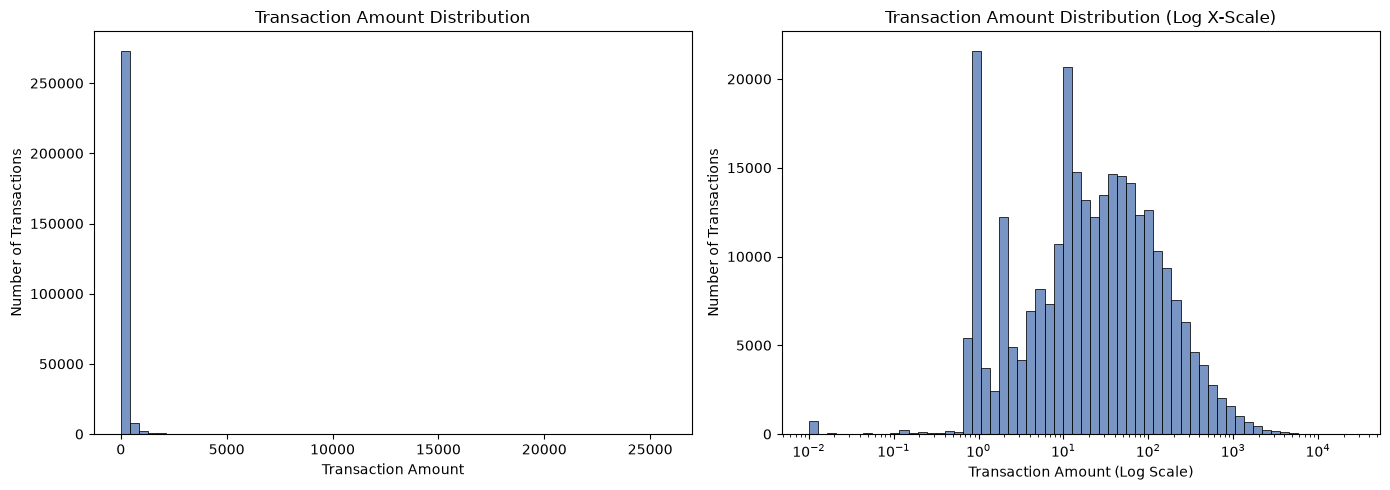

2026-11-01 09:10:23,688 | INFO | Saved amount distribution figure: c:\Users\use\Desktop\Credit Card Fraud Detection\reports\figures\transaction_amount_distribution.png


In [8]:
def plot_amount_distribution(
    dataframe: pd.DataFrame,
    output_path: Path,
) -> None:
    """Plot the overall transaction-amount distribution."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    sns.histplot(
        data=dataframe,
        x=AMOUNT_COLUMN,
        bins=60,
        kde=False,
        ax=axes[0],
        color="#4C72B0",
    )
    axes[0].set_title("Transaction Amount Distribution")
    axes[0].set_xlabel("Transaction Amount")
    axes[0].set_ylabel("Number of Transactions")

    sns.histplot(
        data=dataframe,
        x=AMOUNT_COLUMN,
        bins=60,
        log_scale=(True, False),
        ax=axes[1],
        color="#4C72B0",
    )
    axes[1].set_title("Transaction Amount Distribution (Log X-Scale)")
    axes[1].set_xlabel("Transaction Amount (Log Scale)")
    axes[1].set_ylabel("Number of Transactions")

    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


amount_distribution_path = FIGURES_DIR / "transaction_amount_distribution.png"
plot_amount_distribution(creditcard_df, amount_distribution_path)

logger.info("Saved amount distribution figure: %s", amount_distribution_path)

## Transaction amount by class

This cell compares transaction amounts across legitimate and fraudulent
transactions using:

- A class-separated histogram with a logarithmic x-axis.
- A box plot with a symmetric logarithmic y-axis.

The plots help identify differences and overlap between the two classes.
However, transaction amount alone is not sufficient to classify a transaction
as fraudulent.

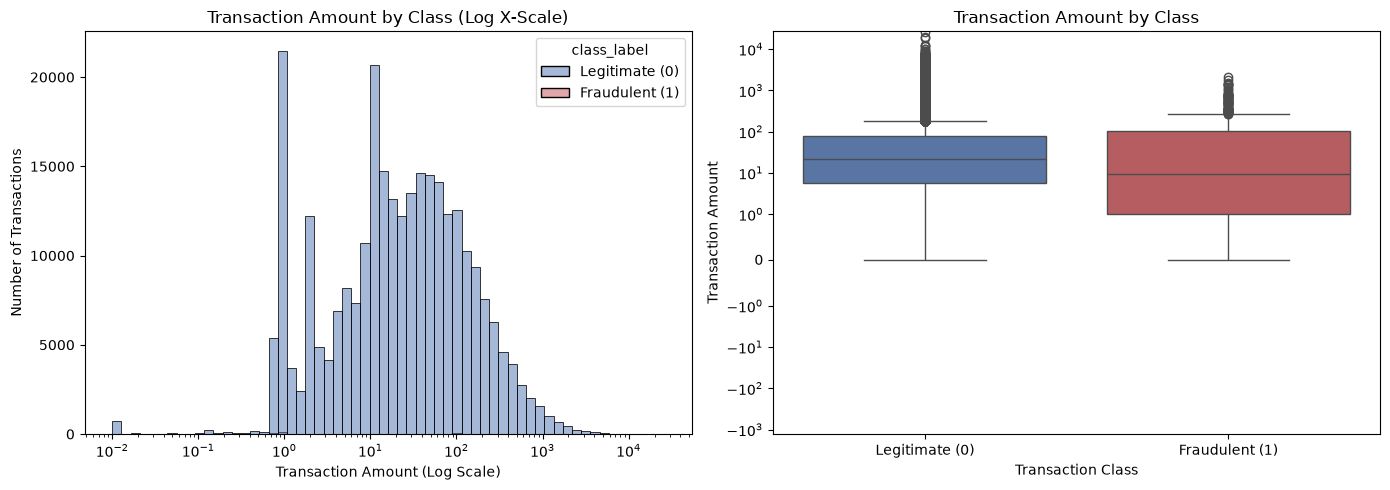

2026-11-01 09:10:33,529 | INFO | Saved amount-by-class figures.


In [9]:
def plot_amount_by_class(
    dataframe: pd.DataFrame,
    distribution_output_path: Path,
    boxplot_output_path: Path,
) -> None:
    """Compare transaction amounts across classes."""
    class_labels = {0: "Legitimate (0)", 1: "Fraudulent (1)"}
    plot_data = dataframe[[TARGET_COLUMN, AMOUNT_COLUMN]].copy()
    plot_data["class_label"] = plot_data[TARGET_COLUMN].map(class_labels)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    sns.histplot(
        data=plot_data,
        x=AMOUNT_COLUMN,
        hue="class_label",
        bins=60,
        log_scale=(True, False),
        palette=["#4C72B0", "#C44E52"],
        multiple="layer",
        ax=axes[0],
    )
    axes[0].set_title("Transaction Amount by Class (Log X-Scale)")
    axes[0].set_xlabel("Transaction Amount (Log Scale)")
    axes[0].set_ylabel("Number of Transactions")

    sns.boxplot(
        data=plot_data,
        x="class_label",
        y=AMOUNT_COLUMN,
        hue="class_label",
        palette=["#4C72B0", "#C44E52"],
        legend=False,
        ax=axes[1],
    )
    axes[1].set_yscale("symlog", linthresh=1)
    axes[1].set_title("Transaction Amount by Class")
    axes[1].set_xlabel("Transaction Class")
    axes[1].set_ylabel("Transaction Amount")

    plt.tight_layout()

    for output_path in (distribution_output_path, boxplot_output_path):
        plt.savefig(output_path, dpi=300, bbox_inches="tight")

    plt.show()


amount_by_class_path = FIGURES_DIR / "transaction_amount_by_class.png"
amount_boxplot_path = FIGURES_DIR / "transaction_amount_boxplot.png"

plot_amount_by_class(
    dataframe=creditcard_df,
    distribution_output_path=amount_by_class_path,
    boxplot_output_path=amount_boxplot_path,
)

logger.info("Saved amount-by-class figures.")

## Elapsed-time analysis

This cell summarizes the `Time` feature separately for legitimate and
fraudulent transactions.

The `Time` column represents elapsed seconds from the first transaction in
the dataset. It is not a calendar timestamp, so it cannot be interpreted as an
actual hour of day, day of week, or date.

In [10]:
def analyze_time_feature(dataframe: pd.DataFrame) -> pd.DataFrame:
    """Summarize elapsed-time statistics by class."""
    summary = (
        dataframe.groupby(TARGET_COLUMN)[TIME_COLUMN]
        .agg(
            count="count",
            mean="mean",
            median="median",
            std="std",
            minimum="min",
            maximum="max",
        )
        .rename(index={0: "Legitimate (0)", 1: "Fraudulent (1)"})
    )

    summary["duration_hours"] = (
        summary["maximum"] - summary["minimum"]
    ) / 3600

    return summary


time_summary = analyze_time_feature(creditcard_df)
time_summary

,count,mean,median,std,minimum,maximum,duration_hours
Class,,,,,,,
Legitimate (0),284315,94838.202258,84711.0,47484.015786,0.0,172792.0,47.997778
Fraudulent (1),492,80746.806911,75568.5,47835.365138,406.0,170348.0,47.206111


## Time distributions and fraud rate by interval

This cell creates four visualizations:

1. Overall elapsed-time distribution.
2. Elapsed-time distribution by class.
3. Fraud count by one-hour interval.
4. Fraud rate by one-hour interval.

The interval-based fraud rate is descriptive. Some intervals may contain very
few transactions, making their fraud rates unstable. These results should not
be interpreted as proof of a time-based fraud pattern.

2026-11-01 09:10:35,322 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-11-01 09:10:35,334 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-11-01 09:10:35,863 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-11-01 09:10:35,877 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


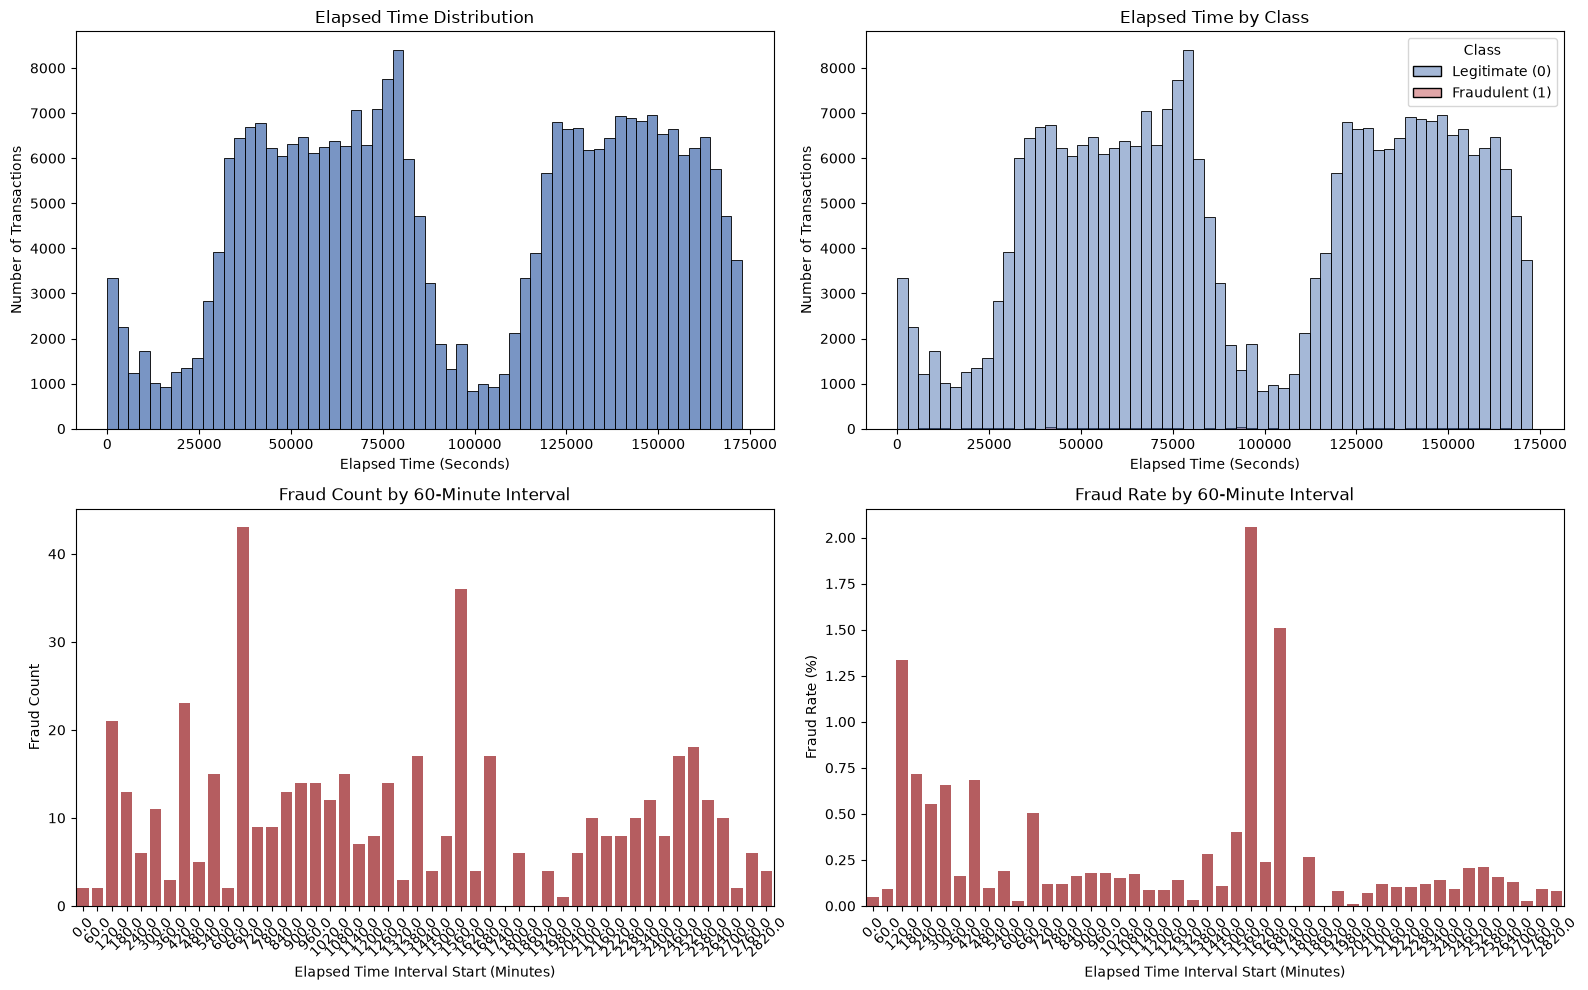

,time_interval_minutes,transaction_count,fraud_count,fraud_rate_percentage
0,0.0,3963,2,0.050467
1,60.0,2217,2,0.090212
2,120.0,1576,21,1.332487
3,180.0,1821,13,0.713893
4,240.0,1082,6,0.554529
5,300.0,1681,11,0.654372
6,360.0,1831,3,0.163845
7,420.0,3368,23,0.682898
8,480.0,5179,5,0.096544
9,540.0,7878,15,0.190404


In [11]:
def plot_time_analysis(
    dataframe: pd.DataFrame,
    time_distribution_path: Path,
    time_by_class_path: Path,
    fraud_rate_path: Path,
    interval_minutes: int = 60,
) -> pd.DataFrame:
    """Plot time distributions and calculate fraud rate by elapsed-time interval."""
    dataframe = dataframe.copy()
    dataframe["time_interval_minutes"] = (
        dataframe[TIME_COLUMN] // (interval_minutes * 60) * interval_minutes
    )

    interval_summary = (
        dataframe.groupby("time_interval_minutes")[TARGET_COLUMN]
        .agg(
            transaction_count="count",
            fraud_count="sum",
        )
        .reset_index()
    )
    interval_summary["fraud_rate_percentage"] = (
        interval_summary["fraud_count"] / interval_summary["transaction_count"] * 100
    )

    fig, axes = plt.subplots(2, 2, figsize=(16, 10))

    sns.histplot(
        data=dataframe,
        x=TIME_COLUMN,
        bins=60,
        ax=axes[0, 0],
        color="#4C72B0",
    )
    axes[0, 0].set_title("Elapsed Time Distribution")
    axes[0, 0].set_xlabel("Elapsed Time (Seconds)")
    axes[0, 0].set_ylabel("Number of Transactions")

    sns.histplot(
        data=dataframe,
        x=TIME_COLUMN,
        hue=dataframe[TARGET_COLUMN].map({0: "Legitimate (0)", 1: "Fraudulent (1)"}),
        bins=60,
        palette=["#4C72B0", "#C44E52"],
        multiple="layer",
        ax=axes[0, 1],
    )
    axes[0, 1].set_title("Elapsed Time by Class")
    axes[0, 1].set_xlabel("Elapsed Time (Seconds)")
    axes[0, 1].set_ylabel("Number of Transactions")

    sns.barplot(
        data=interval_summary,
        x="time_interval_minutes",
        y="fraud_count",
        color="#C44E52",
        ax=axes[1, 0],
    )
    axes[1, 0].set_title(f"Fraud Count by {interval_minutes}-Minute Interval")
    axes[1, 0].set_xlabel("Elapsed Time Interval Start (Minutes)")
    axes[1, 0].set_ylabel("Fraud Count")
    axes[1, 0].tick_params(axis="x", rotation=45)

    sns.barplot(
        data=interval_summary,
        x="time_interval_minutes",
        y="fraud_rate_percentage",
        color="#C44E52",
        ax=axes[1, 1],
    )
    axes[1, 1].set_title(f"Fraud Rate by {interval_minutes}-Minute Interval")
    axes[1, 1].set_xlabel("Elapsed Time Interval Start (Minutes)")
    axes[1, 1].set_ylabel("Fraud Rate (%)")
    axes[1, 1].tick_params(axis="x", rotation=45)

    plt.tight_layout()

    for output_path in (
        time_distribution_path,
        time_by_class_path,
        fraud_rate_path,
    ):
        plt.savefig(output_path, dpi=300, bbox_inches="tight")

    plt.show()

    return interval_summary


time_distribution_path = FIGURES_DIR / "time_distribution.png"
time_by_class_path = FIGURES_DIR / "time_distribution_by_class.png"
fraud_rate_path = FIGURES_DIR / "fraud_rate_by_time_interval.png"

time_interval_summary = plot_time_analysis(
    dataframe=creditcard_df,
    time_distribution_path=time_distribution_path,
    time_by_class_path=time_by_class_path,
    fraud_rate_path=fraud_rate_path,
)

time_interval_summary

## PCA feature summary

This cell calculates descriptive statistics for the anonymized PCA features
`V1` through `V28`.

For each feature, it reports:

- Mean.
- Standard deviation.
- Minimum and maximum.
- 1st and 99th percentiles.

The PCA features are anonymized transformed variables. They do not have known
business meanings, so they must not be interpreted as customer, merchant, or
transaction-category attributes.

In [12]:
def create_pca_feature_summary(dataframe: pd.DataFrame) -> pd.DataFrame:
    """Create descriptive statistics for anonymized PCA features."""
    return (
        dataframe[PCA_FEATURES]
        .agg(
            [
                "mean",
                "std",
                "min",
                "max",
                lambda values: values.quantile(0.01),
                lambda values: values.quantile(0.99),
            ]
        )
        .T.rename(
            columns={
                "<lambda_0>": "p01",
                "<lambda_1>": "p99",
            }
        )
    )


pca_feature_summary = create_pca_feature_summary(creditcard_df)
pca_feature_summary

,mean,std,min,max,<lambda>,<lambda>
V1,1.175161e-15,1.958696,-56.407510,2.454930,-6.563199,2.237130
V2,3.384974e-16,1.651309,-72.715728,22.057729,-4.960300,3.801811
V3,-1.379537e-15,1.516255,-48.325589,9.382558,-3.978377,2.728434
V4,2.094852e-15,1.415869,-5.683171,16.875344,-3.122987,4.248032
V5,1.021879e-15,1.380247,-113.743307,34.801666,-3.060396,3.424903
V6,1.494498e-15,1.332271,-26.160506,73.301626,-2.124023,4.200085
V7,-5.620335e-16,1.237094,-43.557242,120.589494,-3.012847,2.696205
V8,1.149614e-16,1.194353,-73.216718,20.007208,-4.033899,2.075973
V9,-2.414189e-15,1.098632,-13.434066,15.594995,-2.455288,2.986773
V10,2.238554e-15,1.088850,-24.588262,23.745136,-2.092670,3.253618


## PCA feature distributions

This cell plots histograms for all PCA features in manageable groups.

These distributions provide an initial view of feature scale, spread, skewness,
and potential extreme values. The plots are exploratory only; no feature
selection or transformation is performed in this notebook.

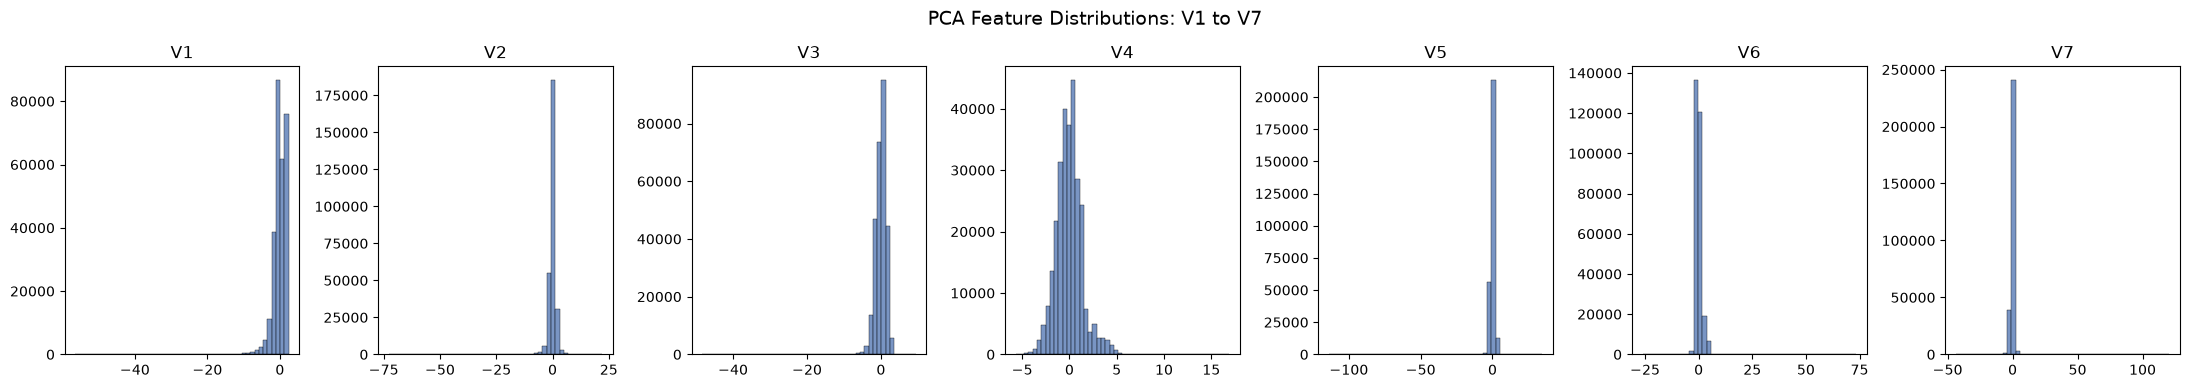

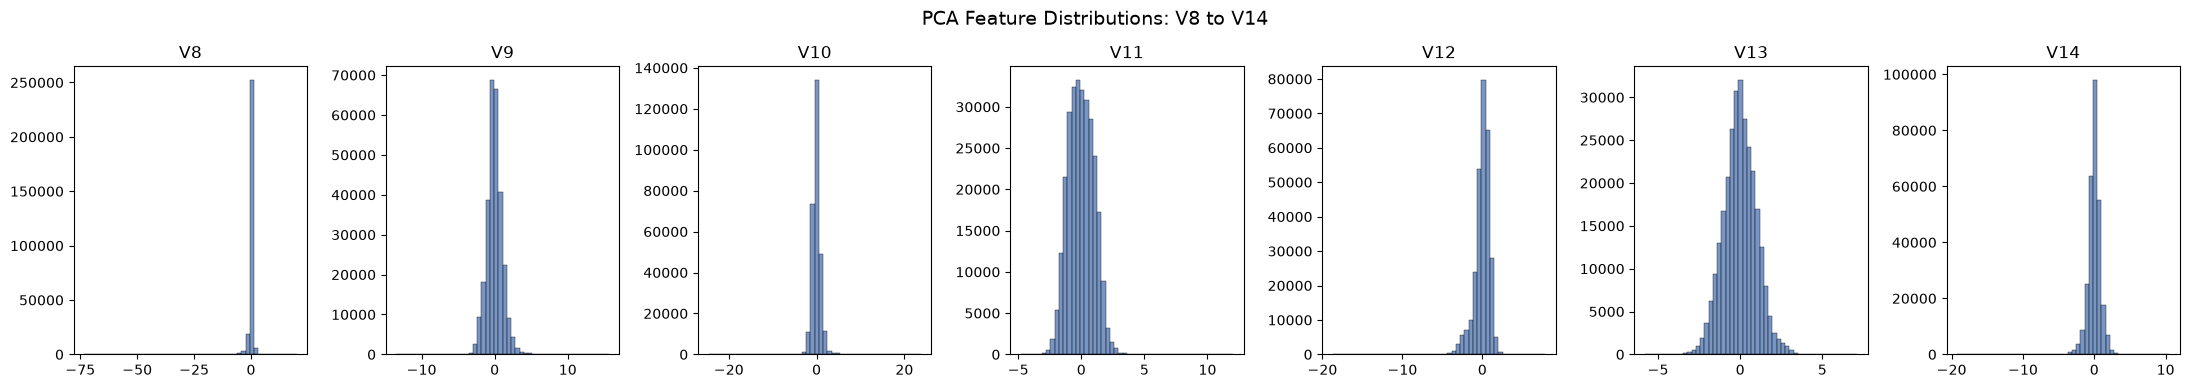

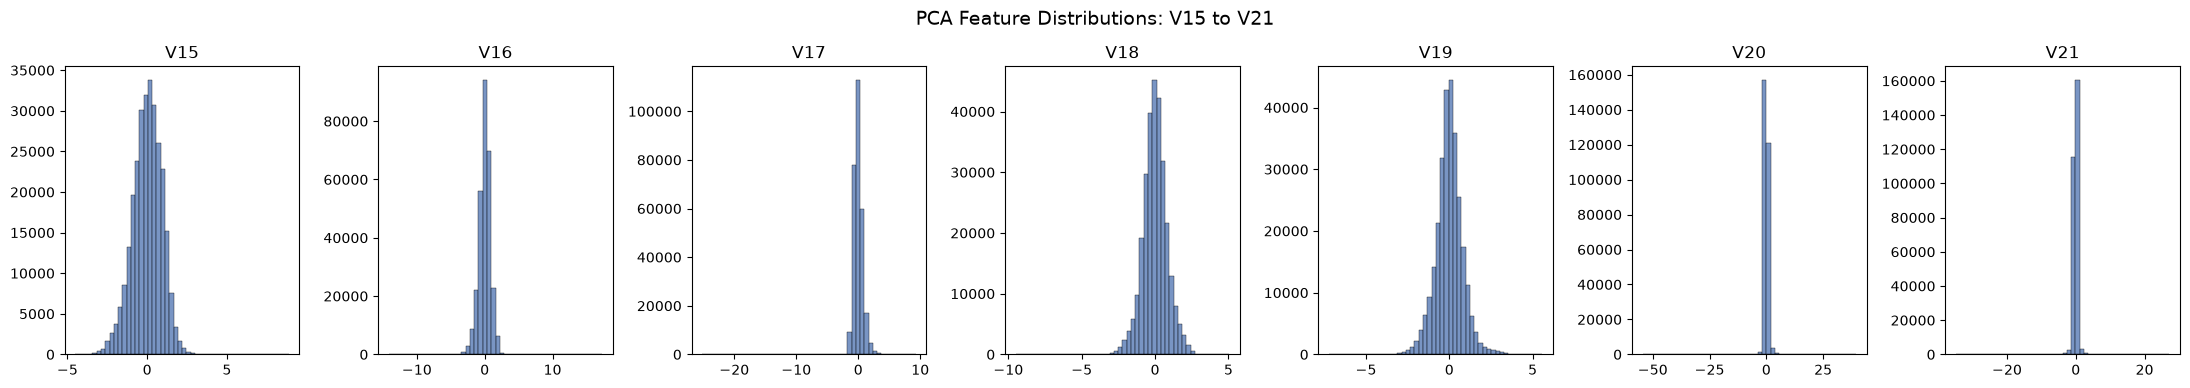

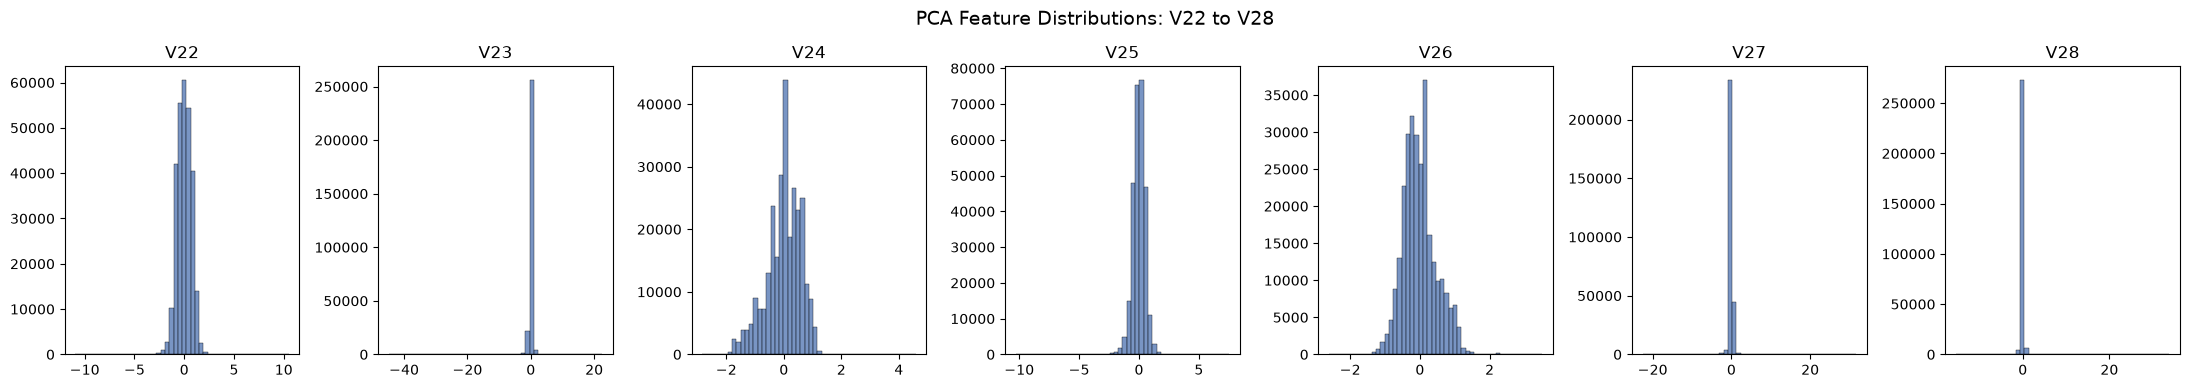

2026-11-01 09:11:21,965 | INFO | Saved 4 PCA feature distribution figures.


In [13]:
def plot_pca_feature_distributions(
    dataframe: pd.DataFrame,
    output_path: Path,
    features_per_figure: int = 7,
) -> list[Path]:
    """Plot histograms for PCA features in manageable groups."""
    output_paths = []

    for group_index in range(0, len(PCA_FEATURES), features_per_figure):
        feature_group = PCA_FEATURES[group_index : group_index + features_per_figure]

        fig, axes = plt.subplots(
            nrows=2,
            ncols=features_per_figure,
            figsize=(22, 7),
        )
        axes = axes.flatten()

        for axis, feature in zip(axes, feature_group):
            sns.histplot(
                data=dataframe,
                x=feature,
                bins=50,
                kde=False,
                ax=axis,
                color="#4C72B0",
            )
            axis.set_title(feature)
            axis.set_xlabel("")
            axis.set_ylabel("")

        for axis in axes[len(feature_group):]:
            axis.set_visible(False)

        fig.suptitle(
            f"PCA Feature Distributions: {feature_group[0]} to {feature_group[-1]}",
            fontsize=14,
        )
        plt.tight_layout()

        output_path = FIGURES_DIR / f"feature_distributions_group_{group_index // features_per_figure + 1}.png"
        plt.savefig(output_path, dpi=300, bbox_inches="tight")
        plt.show()
        output_paths.append(output_path)

    return output_paths


pca_distribution_paths = plot_pca_feature_distributions(
    dataframe=creditcard_df,
    output_path=FIGURES_DIR,
)

logger.info("Saved %d PCA feature distribution figures.", len(pca_distribution_paths))

## Class separation across PCA features

This cell compares the mean values of each PCA feature between legitimate and
fraudulent transactions.

It calculates:

- Mean for each class.
- Absolute mean difference.
- Standardized mean difference.
- Absolute standardized mean difference.

Features with larger absolute standardized mean differences show greater
separation between class means. This is a descriptive screening measure, not a
final feature-selection decision.

In [14]:
def calculate_class_separation_metrics(dataframe: pd.DataFrame) -> pd.DataFrame:
    """Calculate class means and standardized mean differences for PCA features."""
    legitimate = dataframe[dataframe[TARGET_COLUMN] == 0]
    fraudulent = dataframe[dataframe[TARGET_COLUMN] == 1]

    records = []

    for feature in PCA_FEATURES:
        legitimate_mean = legitimate[feature].mean()
        fraudulent_mean = fraudulent[feature].mean()
        pooled_std = np.sqrt(
            (
                legitimate[feature].var(ddof=1) * len(legitimate)
                + fraudulent[feature].var(ddof=1) * len(fraudulent)
            )
            / (len(legitimate) + len(fraudulent) - 2)
        )

        standardized_mean_difference = (
            (fraudulent_mean - legitimate_mean) / pooled_std
            if pooled_std > 0
            else 0.0
        )

        records.append(
            {
                "feature": feature,
                "legitimate_mean": legitimate_mean,
                "fraudulent_mean": fraudulent_mean,
                "mean_difference": fraudulent_mean - legitimate_mean,
                "absolute_mean_difference": abs(fraudulent_mean - legitimate_mean),
                "standardized_mean_difference": standardized_mean_difference,
                "absolute_standardized_mean_difference": abs(standardized_mean_difference),
            }
        )

    return pd.DataFrame(records).sort_values(
        by="absolute_standardized_mean_difference",
        ascending=False,
    ).reset_index(drop=True)


class_separation_summary = calculate_class_separation_metrics(creditcard_df)
class_separation_summary.head(10)

,feature,legitimate_mean,fraudulent_mean,mean_difference,absolute_mean_difference,standardized_mean_difference,absolute_standardized_mean_difference
0,V17,0.011535,-6.665836,-6.677371,6.677371,-8.316510,8.316510
1,V14,0.012064,-6.971723,-6.983787,6.983787,-7.643331,7.643331
2,V12,0.010832,-6.259393,-6.270225,6.270225,-6.499525,6.499525
3,V10,0.009824,-5.676883,-5.686707,5.686707,-5.349799,5.349799
4,V16,0.007164,-4.139946,-4.147110,4.147110,-4.826733,4.826733
5,V3,0.012171,-7.033281,-7.045452,7.045452,-4.735407,4.735407
6,V7,0.009637,-5.568731,-5.578368,5.578368,-4.590154,4.590154
7,V11,-0.006576,3.800173,3.806749,3.806749,3.774990,3.774990
8,V4,-0.007860,4.542029,4.549889,4.549889,3.242463,3.242463
9,V18,0.003887,-2.246308,-2.250195,2.250195,-2.701407,2.701407


## Class-separated distributions for selected features

This cell plots density distributions for the eight PCA features with the
largest absolute standardized mean differences.

The plots show how the distributions differ between legitimate and fraudulent
transactions. Differences in distribution do not prove causation, and a
feature that appears visually separated may not necessarily improve
out-of-sample model performance.

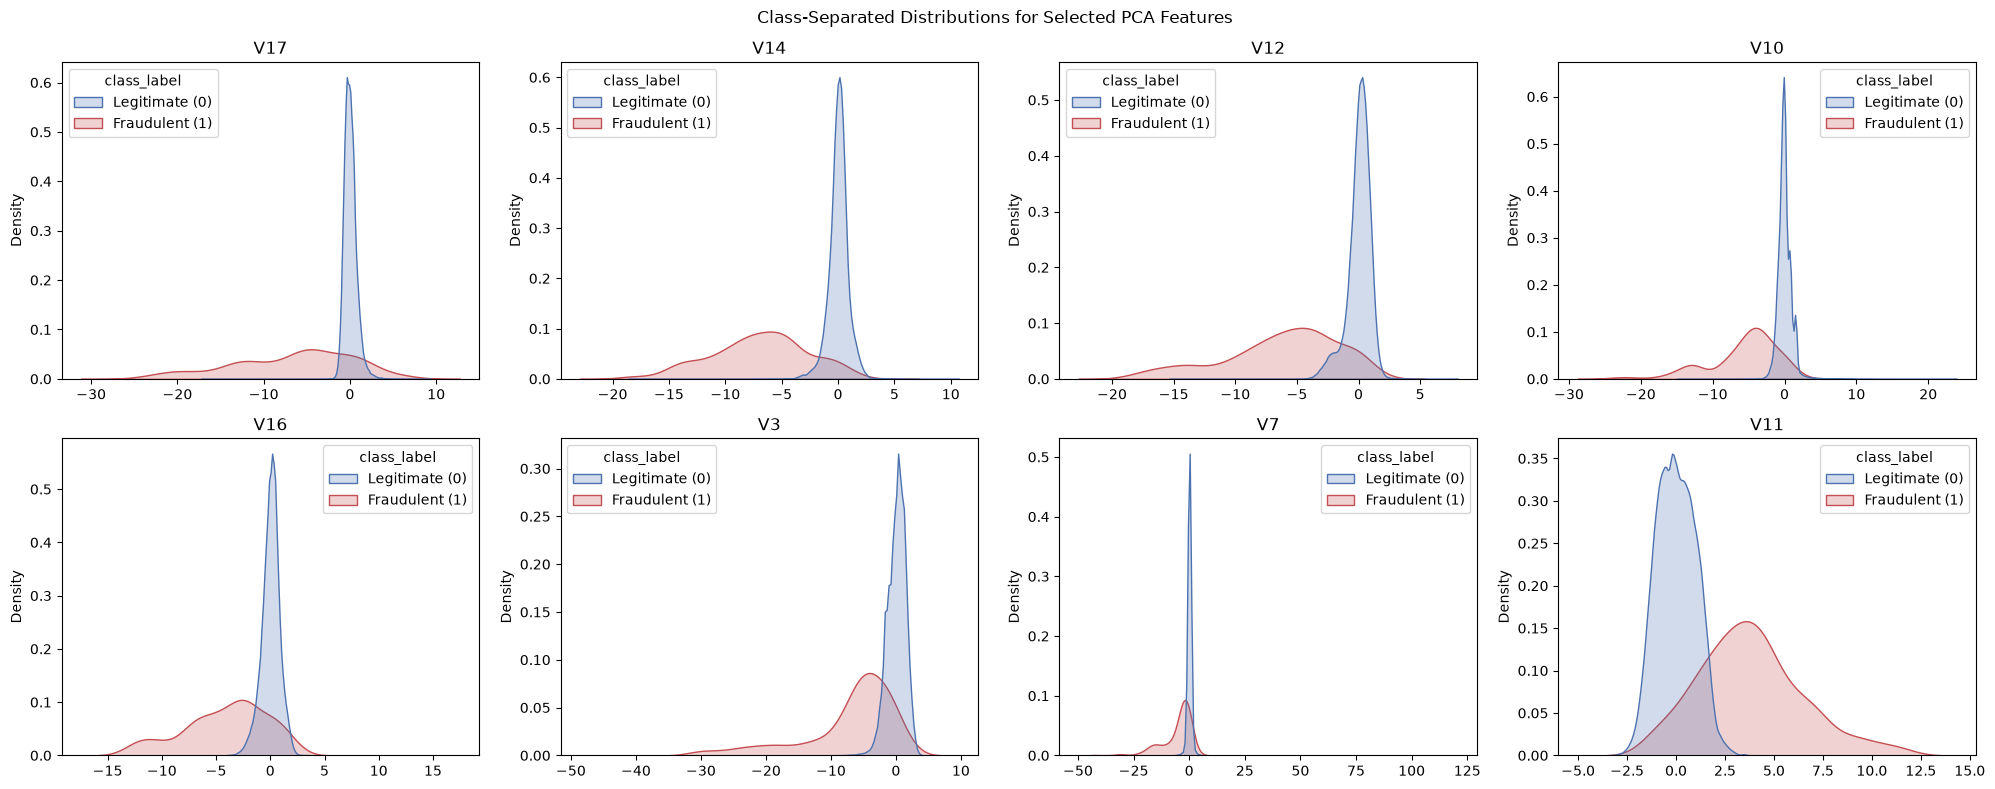

2026-11-01 09:11:51,510 | INFO | Selected features for visualization: ['V17', 'V14', 'V12', 'V10', 'V16', 'V3', 'V7', 'V11']


In [15]:
def plot_selected_features_by_class(
    dataframe: pd.DataFrame,
    features: list[str],
    output_path: Path,
) -> None:
    """Plot class-separated distributions for selected PCA features."""
    class_labels = {0: "Legitimate (0)", 1: "Fraudulent (1)"}
    plot_data = dataframe[features + [TARGET_COLUMN]].copy()
    plot_data["class_label"] = plot_data[TARGET_COLUMN].map(class_labels)

    fig, axes = plt.subplots(2, 4, figsize=(20, 8))
    axes = axes.flatten()

    for axis, feature in zip(axes, features):
        sns.kdeplot(
            data=plot_data,
            x=feature,
            hue="class_label",
            common_norm=False,
            fill=True,
            palette=["#4C72B0", "#C44E52"],
            ax=axis,
        )
        axis.set_title(feature)
        axis.set_xlabel("")
        axis.set_ylabel("Density")

    for axis in axes[len(features):]:
        axis.set_visible(False)

    fig.suptitle("Class-Separated Distributions for Selected PCA Features")
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


selected_features = class_separation_summary.head(8)["feature"].tolist()
feature_by_class_path = FIGURES_DIR / "feature_distributions_by_class.png"

plot_selected_features_by_class(
    dataframe=creditcard_df,
    features=selected_features,
    output_path=feature_by_class_path,
)

logger.info("Selected features for visualization: %s", selected_features)

## Correlation analysis

This cell calculates Pearson correlations between numerical features and
between each feature and the `Class` target.

The results are sorted by absolute correlation with the target. Correlation
describes linear association only. It does not establish causation and does
not guarantee that a feature will be useful to a nonlinear model such as
Random Forest.

In [16]:
def calculate_correlations(dataframe: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series]:
    """Calculate feature correlations and target correlations."""
    correlation_matrix = dataframe.corr(method="pearson")
    target_correlations = correlation_matrix[TARGET_COLUMN].drop(TARGET_COLUMN)

    return correlation_matrix, target_correlations


correlation_matrix, target_correlations = calculate_correlations(creditcard_df)

target_correlation_summary = (
    target_correlations.to_frame("pearson_correlation_with_class")
    .assign(
        absolute_correlation=lambda data: data[
            "pearson_correlation_with_class"
        ].abs()
    )
    .sort_values(by="absolute_correlation", ascending=False)
)

target_correlation_summary

,pearson_correlation_with_class,absolute_correlation
V17,-0.326481,0.326481
V14,-0.302544,0.302544
V12,-0.260593,0.260593
V10,-0.216883,0.216883
V16,-0.196539,0.196539
V3,-0.192961,0.192961
V7,-0.187257,0.187257
V11,0.154876,0.154876
V4,0.133447,0.133447
V18,-0.111485,0.111485


## Correlation heatmap

This cell creates a Pearson correlation heatmap for all numerical features.

The heatmap helps identify potential linear relationships and possible feature
redundancy. Correlated features are not automatically removed; feature
selection and its effect on model performance are evaluated in later phases.

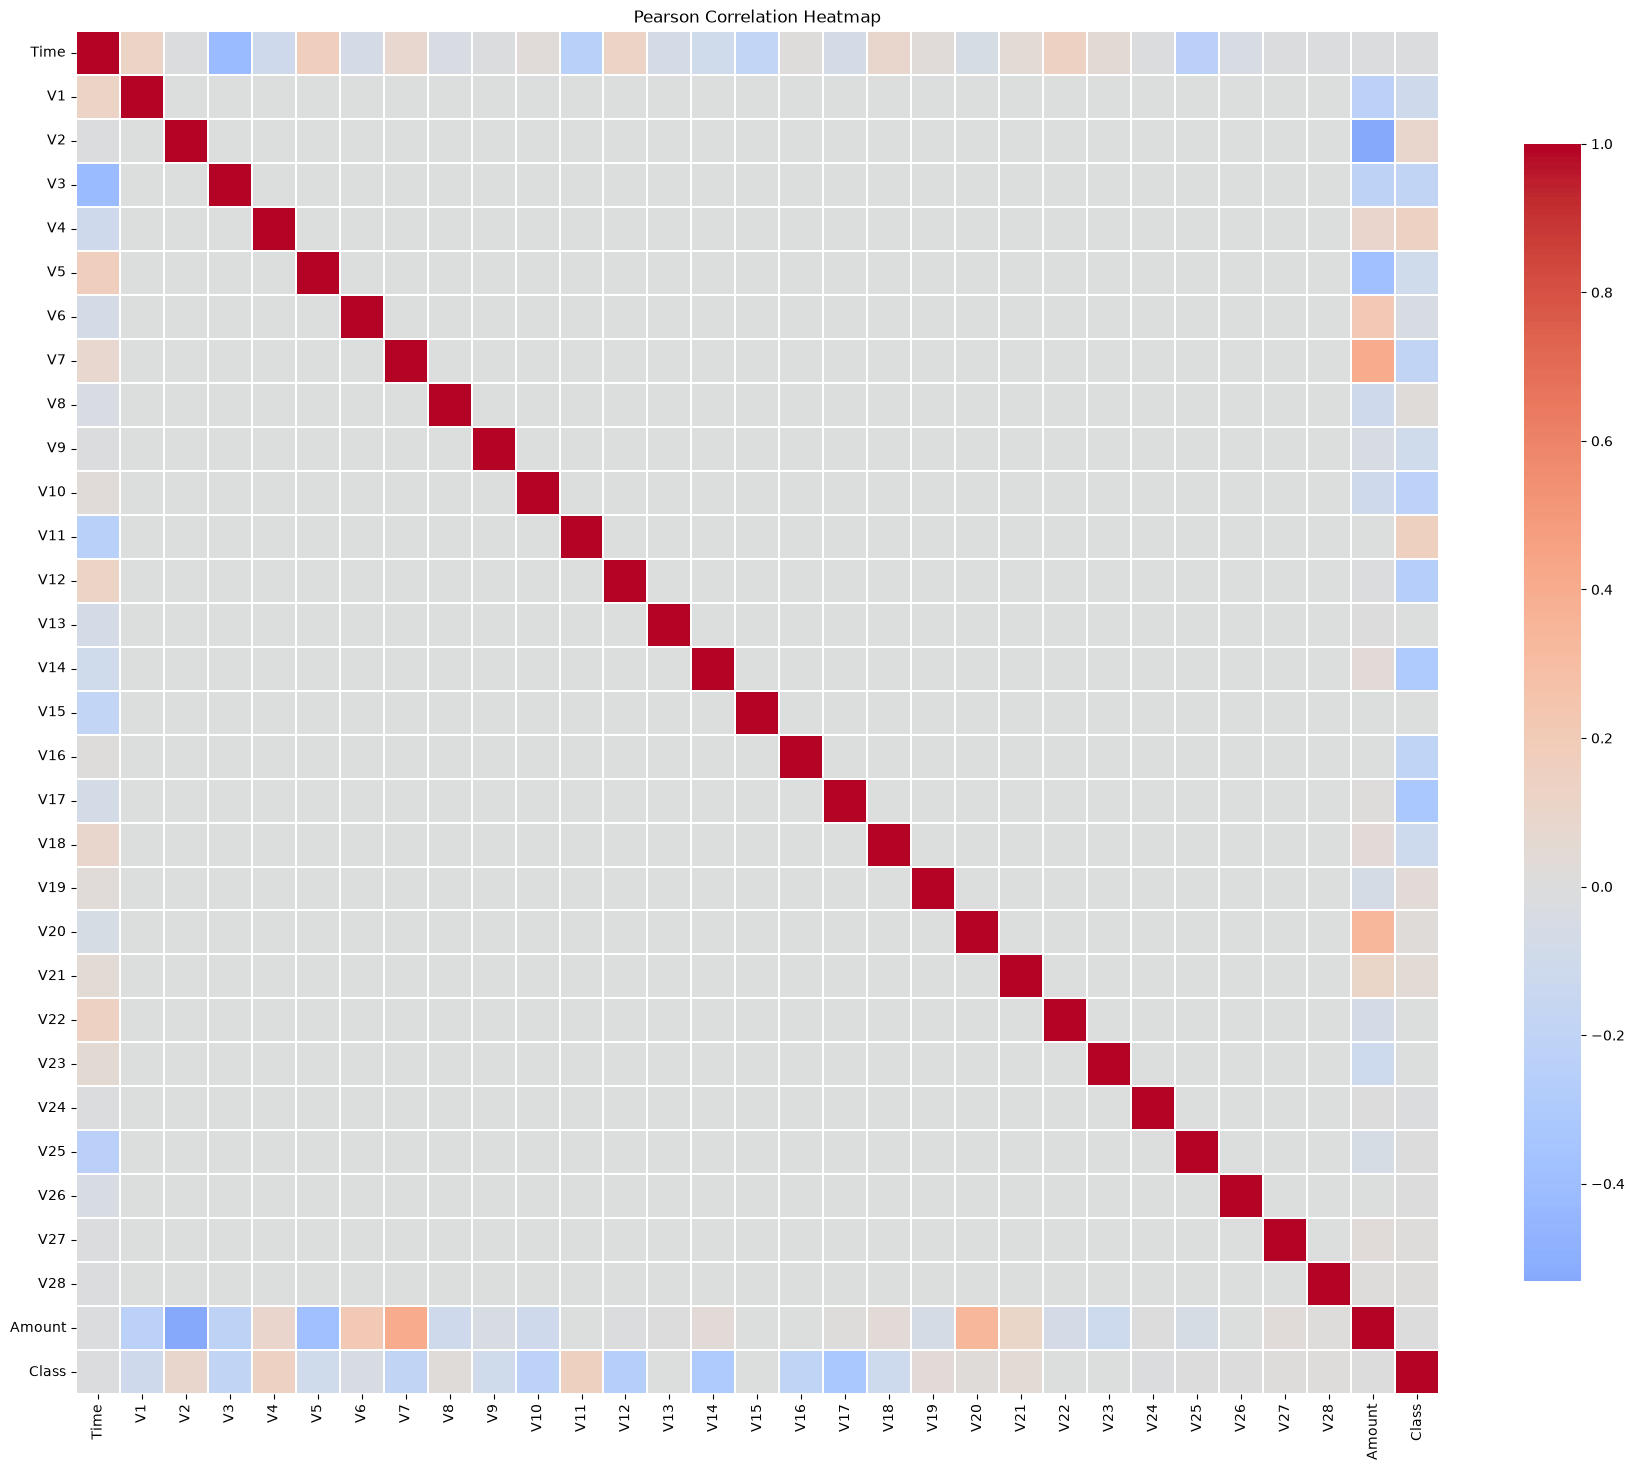

2026-11-01 09:11:54,718 | INFO | Saved correlation heatmap: c:\Users\use\Desktop\Credit Card Fraud Detection\reports\figures\correlation_heatmap.png


In [17]:
def plot_correlation_heatmap(
    correlation_matrix: pd.DataFrame,
    output_path: Path,
) -> None:
    """Plot a readable correlation heatmap."""
    plt.figure(figsize=(18, 15))

    sns.heatmap(
        correlation_matrix,
        cmap="coolwarm",
        center=0,
        annot=False,
        square=True,
        linewidths=0.2,
        cbar_kws={"shrink": 0.8},
    )

    plt.title("Pearson Correlation Heatmap")
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


correlation_heatmap_path = FIGURES_DIR / "correlation_heatmap.png"
plot_correlation_heatmap(correlation_matrix, correlation_heatmap_path)

logger.info("Saved correlation heatmap: %s", correlation_heatmap_path)

## Potential outlier analysis

This cell identifies descriptive outlier candidates without removing or
modifying any records.

Two checks are performed:

1. Transactions with amounts above the 99th percentile.
2. Transactions with an absolute z-score greater than 5 for any PCA feature.

An outlier candidate is not automatically an invalid record or a fraudulent
transaction. Legitimate transactions can also have extreme values.

In [18]:
def identify_potential_outliers(
    dataframe: pd.DataFrame,
    amount_upper_quantile: float = 0.99,
    pca_zscore_threshold: float = 5.0,
) -> dict:
    """Identify descriptive outlier candidates without removing them."""
    amount_threshold = dataframe[AMOUNT_COLUMN].quantile(amount_upper_quantile)
    high_amount_transactions = dataframe[
        dataframe[AMOUNT_COLUMN] > amount_threshold
    ]

    pca_zscores = dataframe[PCA_FEATURES].apply(
        lambda column: (column - column.mean()) / column.std(ddof=0)
    )

    pca_outlier_mask = (pca_zscores.abs() > pca_zscore_threshold).any(axis=1)

    return {
        "amount_threshold": float(amount_threshold),
        "high_amount_transaction_count": int(len(high_amount_transactions)),
        "high_amount_fraud_count": int(high_amount_transactions[TARGET_COLUMN].sum()),
        "high_amount_legitimate_count": int(
            (high_amount_transactions[TARGET_COLUMN] == 0).sum()
        ),
        "pca_zscore_threshold": pca_zscore_threshold,
        "pca_outlier_candidate_count": int(pca_outlier_mask.sum()),
        "pca_outlier_fraud_count": int(
            dataframe.loc[pca_outlier_mask, TARGET_COLUMN].sum()
        ),
        "pca_outlier_legitimate_count": int(
            (dataframe.loc[pca_outlier_mask, TARGET_COLUMN] == 0).sum()
        ),
    }


potential_outlier_summary = identify_potential_outliers(creditcard_df)

print(json.dumps(potential_outlier_summary, indent=2))

{
  "amount_threshold": 1017.9700000000012,
  "high_amount_transaction_count": 2849,
  "high_amount_fraud_count": 9,
  "high_amount_legitimate_count": 2840,
  "pca_zscore_threshold": 5.0,
  "pca_outlier_candidate_count": 7952,
  "pca_outlier_fraud_count": 407,
  "pca_outlier_legitimate_count": 7545
}


## Visualize potential outliers

This cell plots:

- Transaction amount by class using a symmetric logarithmic scale.
- `V14` versus `V17`.
- `V12` versus `V14`.

These selected feature relationships help inspect whether extreme values occur
in both classes. The visualization is exploratory and does not classify any
transaction as fraudulent.

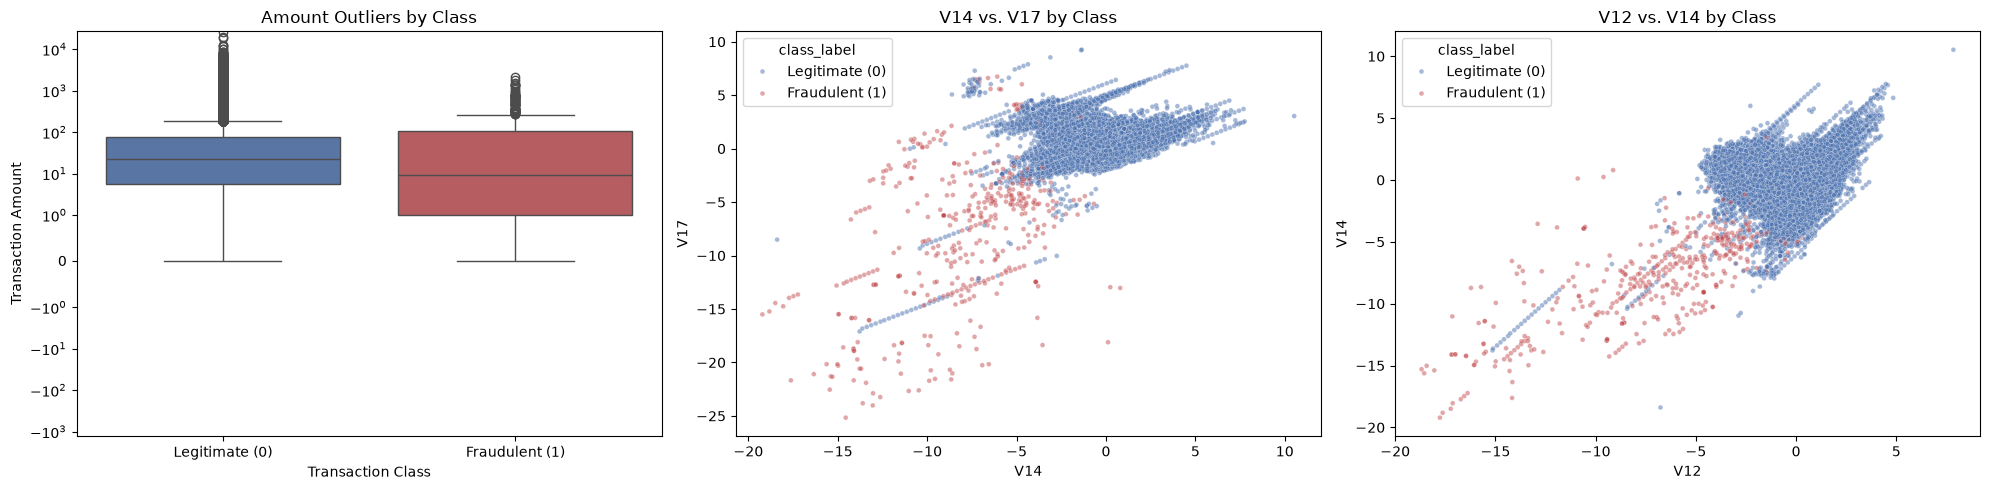

2026-11-01 09:12:48,123 | INFO | Saved potential outlier figure: c:\Users\use\Desktop\Credit Card Fraud Detection\reports\figures\potential_outliers.png


In [19]:
def plot_potential_outliers(
    dataframe: pd.DataFrame,
    output_path: Path,
) -> None:
    """Plot selected relationships relevant to potential outliers."""
    plot_data = dataframe.copy()
    plot_data["class_label"] = plot_data[TARGET_COLUMN].map(
        {0: "Legitimate (0)", 1: "Fraudulent (1)"}
    )

    fig, axes = plt.subplots(1, 3, figsize=(20, 5))

    sns.boxplot(
        data=plot_data,
        x="class_label",
        y=AMOUNT_COLUMN,
        hue="class_label",
        palette=["#4C72B0", "#C44E52"],
        legend=False,
        ax=axes[0],
    )
    axes[0].set_yscale("symlog", linthresh=1)
    axes[0].set_title("Amount Outliers by Class")
    axes[0].set_xlabel("Transaction Class")
    axes[0].set_ylabel("Transaction Amount")

    sns.scatterplot(
        data=plot_data,
        x="V14",
        y="V17",
        hue="class_label",
        palette=["#4C72B0", "#C44E52"],
        alpha=0.5,
        s=12,
        ax=axes[1],
    )
    axes[1].set_title("V14 vs. V17 by Class")
    axes[1].set_xlabel("V14")
    axes[1].set_ylabel("V17")

    sns.scatterplot(
        data=plot_data,
        x="V12",
        y="V14",
        hue="class_label",
        palette=["#4C72B0", "#C44E52"],
        alpha=0.5,
        s=12,
        ax=axes[2],
    )
    axes[2].set_title("V12 vs. V14 by Class")
    axes[2].set_xlabel("V12")
    axes[2].set_ylabel("V14")

    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


potential_outliers_path = FIGURES_DIR / "potential_outliers.png"
plot_potential_outliers(creditcard_df, potential_outliers_path)

logger.info("Saved potential outlier figure: %s", potential_outliers_path)

## Build EDA findings

This cell combines the main computed results into a structured findings
dictionary.

It records:

- Dataset overview and quality.
- Class distribution.
- Transaction-amount statistics.
- Time statistics.
- Strongest target correlations.
- Most-separated PCA features.
- Potential outlier summary.
- Implications for later phases.

All values are calculated from the loaded dataset; no metrics are invented.

In [20]:
def build_eda_findings(
    overview: dict,
    class_summary: pd.DataFrame,
    amount_summary: pd.DataFrame,
    time_summary: pd.DataFrame,
    separation_summary: pd.DataFrame,
    target_correlations: pd.Series,
    outlier_summary: dict,
) -> dict:
    """Build an EDA findings dictionary using actual computed results."""
    strongest_target_correlations = (
        target_correlations.reindex(
            target_correlations.abs().sort_values(ascending=False).index
        )
        .head(10)
        .to_dict()
    )

    return {
        "dataset_overview": overview,
        "class_distribution": {
            "legitimate_count": int(class_summary.loc["Legitimate (0)", "count"]),
            "fraudulent_count": int(class_summary.loc["Fraudulent (1)", "count"]),
            "legitimate_percentage": float(
                class_summary.loc["Legitimate (0)", "percentage"]
            ),
            "fraudulent_percentage": float(
                class_summary.loc["Fraudulent (1)", "percentage"]
            ),
        },
        "amount_analysis": amount_summary.to_dict(),
        "time_analysis": time_summary.to_dict(),
        "strongest_absolute_target_correlations": strongest_target_correlations,
        "most_separated_pca_features": separation_summary.head(10).to_dict(
            orient="records"
        ),
        "potential_outliers": outlier_summary,
        "implications_for_later_phases": [
            "Duplicate records must be investigated before deciding whether to retain or remove them.",
            "The extreme class imbalance requires evaluation using precision, recall, F1-score, PR-AUC, and confusion matrices.",
            "Amount is highly skewed; transformations may be investigated later but must not be applied solely to remove outliers.",
            "Time is elapsed seconds, not calendar time; no hour-of-day or day-of-week features can be derived reliably.",
            "PCA features are anonymized and must not be assigned business meanings.",
            "Potential outliers are candidates for investigation, not confirmed fraud or invalid records.",
        ],
    }


eda_findings = build_eda_findings(
    overview=dataset_overview,
    class_summary=class_distribution,
    amount_summary=amount_summary,
    time_summary=time_summary,
    separation_summary=class_separation_summary,
    target_correlations=target_correlations,
    outlier_summary=potential_outlier_summary,
)

logger.info("EDA findings constructed successfully.")

2026-11-01 09:12:48,154 | INFO | EDA findings constructed successfully.


## Generate and validate EDA report

This cell writes the exploratory findings to:

```text
reports/eda_report.md
```

The report summarizes the dataset, target imbalance, transaction amounts,
elapsed-time feature, correlations, and potential outliers. It also documents
limitations and implications for later preprocessing and modeling phases.

The cell then verifies that all expected figures and the EDA report were
created. If any artifact is missing, the notebook raises an error rather than
silently claiming success.

In [21]:
def write_eda_report(findings: dict, output_path: Path) -> None:
    """Write a concise EDA report based on actual findings."""
    overview = findings["dataset_overview"]
    class_distribution = findings["class_distribution"]
    outliers = findings["potential_outliers"]

    strongest_correlations = findings[
        "strongest_absolute_target_correlations"
    ]
    strongest_correlations_text = "\n".join(
        f"- `{feature}`: {correlation:.4f}"
        for feature, correlation in strongest_correlations.items()
    )

    report = f"""# Exploratory Data Analysis Report

## Dataset Overview

- Rows: {overview['row_count']:,}
- Columns: {overview['column_count']}
- Numerical columns: {overview['numerical_column_count']}
- Categorical columns: {overview['categorical_column_count']}
- Missing values: {overview['total_missing_values']}
- Duplicate rows: {overview['duplicate_row_count']:,} ({overview['duplicate_row_percentage']:.3f}%)

## Target Distribution

- Legitimate transactions: {class_distribution['legitimate_count']:,}
- Fraudulent transactions: {class_distribution['fraudulent_count']:,}
- Legitimate percentage: {class_distribution['legitimate_percentage']:.3f}%
- Fraudulent percentage: {class_distribution['fraudulent_percentage']:.3f}%

The dataset is extremely imbalanced. Accuracy alone is not an appropriate primary evaluation metric.

## Transaction Amount

Fraudulent transactions have a higher mean amount but a lower median amount than legitimate transactions. This indicates skewness and substantial distribution overlap. Transaction amount alone must not be used to classify fraud.

## Time Feature

`Time` represents elapsed seconds from the first transaction and covers approximately 48 hours. It must not be interpreted as a calendar timestamp, hour of day, or day of week.

## Feature Correlations

The strongest absolute Pearson correlations with `Class` are:

{strongest_correlations_text}

These correlations describe linear associations only. They do not establish causation or guarantee predictive value for nonlinear models.

## Potential Outliers

- High-amount threshold (99th percentile): {outliers['amount_threshold']:.2f}
- High-amount transactions: {outliers['high_amount_transaction_count']:,}
- High-amount fraudulent transactions: {outliers['high_amount_fraud_count']}
- High-amount legitimate transactions: {outliers['high_amount_legitimate_count']:,}
- PCA z-score outlier candidates: {outliers['pca_outlier_candidate_count']:,}
- PCA outlier candidates that are fraudulent: {outliers['pca_outlier_fraud_count']}
- PCA outlier candidates that are legitimate: {outliers['pca_outlier_legitimate_count']:,}

Potential outliers are observations for further investigation. They are not automatically invalid records or confirmed fraud cases.

## Implications for Later Phases

{chr(10).join(f'- {item}' for item in findings['implications_for_later_phases'])}
"""

    output_path.write_text(report, encoding="utf-8")


write_eda_report(eda_findings, EDA_REPORT_PATH)

required_artifacts = [
    class_distribution_path,
    amount_distribution_path,
    amount_by_class_path,
    amount_boxplot_path,
    time_distribution_path,
    time_by_class_path,
    fraud_rate_path,
    feature_by_class_path,
    correlation_heatmap_path,
    potential_outliers_path,
    EDA_REPORT_PATH,
]

missing_artifacts = [path for path in required_artifacts if not path.exists()]

if missing_artifacts:
    raise FileNotFoundError(
        f"Missing expected EDA artifacts: {[str(path) for path in missing_artifacts]}"
    )

logger.info("All required EDA artifacts were generated successfully.")
logger.info("EDA report saved to: %s", EDA_REPORT_PATH)

2026-11-01 09:12:48,184 | INFO | All required EDA artifacts were generated successfully.
2026-11-01 09:12:48,186 | INFO | EDA report saved to: c:\Users\use\Desktop\Credit Card Fraud Detection\reports\eda_report.md


## Generated EDA artifacts

This final cell lists the EDA figures generated in `reports/figures/` and
confirms the location of the saved EDA report.

At this point, exploratory data analysis is complete. The dataset has been
analyzed and documented, but no cleaning, feature engineering, resampling,
model training, or threshold selection has been performed.

In [22]:
generated_artifacts = sorted(
    path.name
    for path in FIGURES_DIR.glob("*.png")
)

print("Generated EDA figures:")
for artifact_name in generated_artifacts:
    print(f"- {artifact_name}")

print(f"\nEDA report: {EDA_REPORT_PATH.name}")

Generated EDA figures:
- class_distribution.png
- correlation_heatmap.png
- feature_distributions_by_class.png
- feature_distributions_group_1.png
- feature_distributions_group_2.png
- feature_distributions_group_3.png
- feature_distributions_group_4.png
- fraud_rate_by_time_interval.png
- potential_outliers.png
- time_distribution.png
- time_distribution_by_class.png
- transaction_amount_boxplot.png
- transaction_amount_by_class.png
- transaction_amount_distribution.png

EDA report: eda_report.md
